<a href="https://colab.research.google.com/github/anastasiatam/Engineering-with-Machine-Learning/blob/main/homework5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Question 1**

In [11]:
import tensorflow as tf
from tensorflow.keras import layers, models
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Load and Preprocess CIFAR-10 Dataset
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()

# Normalize pixel values to be between 0 and 1
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

# Input dimensions for CIFAR-10 images: (32, 32, 3)
input_shape = x_train.shape[1:]

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 4655s 27us/step


In [5]:
# Save the processed data for future use
np.savez_compressed(
    "cifar10_data.npz",
    x_train=x_train,
    y_train=y_train,
    x_test=x_test,
    y_test=y_test,
)

# Load data
(x_train, y_train, x_test, y_test) = [
    np.load("cifar10_data.npz")[k]
    for k in ("x_train", "y_train", "x_test", "y_test")
]
input_shape = x_train.shape[1:]

In [6]:
# Build the CNN Architecture
model = models.Sequential([
    # Layer 1: 2D Conv layer with 64 filters of size (5, 5), ReLU activation
    layers.Conv2D(64, (5, 5), activation='relu', input_shape=input_shape, name="layer_1_conv2d"),

    # Layer 2: Max pooling layer of size (2, 2)
    layers.MaxPooling2D((2, 2), name="layer_2_maxpool"),

    # Layer 3: 2D Conv layer with 32 filters of size (3, 3), ReLU activation
    layers.Conv2D(32, (3, 3), activation='relu', name="layer_3_conv2d"),

    # Layer 4: Max pooling layer of size (2, 2)
    layers.MaxPooling2D((2, 2), name="layer_4_maxpool"),

    # Layer 5: 2D Conv layer with 32 filters of size (3, 3), ReLU activation
    layers.Conv2D(32, (3, 3), activation='relu', name="layer_5_conv2d"),

    # Layer 6: Flatten layer
    layers.Flatten(name="layer_6_flatten"),

    # Layer 7: Dense layer with 64 neurons, ReLU activation
    layers.Dense(64, activation='relu', name="layer_7_dense"),

    # Layer 8: Dense layer with 10 output neurons, Softmax for class probabilities
    layers.Dense(10, activation='softmax', name="layer_8_output")
])

# Display architecture summary
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ layer_1_conv2d (Conv2D)         │ (None, 28, 28, 64)     │         4,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_2_maxpool (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_3_conv2d (Conv2D)         │ (None, 12, 12, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_4_maxpool (MaxPooling2D)  │ (None, 6, 6, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_5_conv2d (Conv2D)         │ (None, 4, 4, 32)       │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_6_flatten (Flatten)       │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_7_dense (Dense)           │ (None, 64)             │        32,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_8_output (Dense)          │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 66,058 (258.04 KB)

 Trainable params: 66,058 (258.04 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
# Compile and Train Model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Train the model
history = model.fit(
    x_train, y_train,
    epochs=10,
    batch_size=64,
    validation_data=(x_test, y_test)
)

Epoch 1/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 100s 126ms/step - accuracy: 0.4021 - loss: 1.6318 - val_accuracy: 0.5014 - val_loss: 1.3684
Epoch 2/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 91s 117ms/step - accuracy: 0.5288 - loss: 1.3192 - val_accuracy: 0.5703 - val_loss: 1.2168
Epoch 3/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 144s 120ms/step - accuracy: 0.5902 - loss: 1.1653 - val_accuracy: 0.6073 - val_loss: 1.1061
Epoch 4/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 140s 117ms/step - accuracy: 0.6281 - loss: 1.0623 - val_accuracy: 0.6238 - val_loss: 1.0674
Epoch 5/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 92s 117ms/step - accuracy: 0.6538 - loss: 0.9864 - val_accuracy: 0.6549 - val_loss: 0.9939
Epoch 6/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 92s 118ms/step - accuracy: 0.6756 - loss: 0.9266 - val_accuracy: 0.6612 - val_loss: 0.9726
Epoch 7/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 141s 117ms/step - accuracy: 0.6885 - loss: 0.8886 - val_accuracy: 0.6697 - val_loss: 0.9592
Epoch 8/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 143s 118ms/step - accuracy: 0.7051 - lo

In [9]:
# Extract and Print Accuracies
final_train_acc = history.history['accuracy'][-1]
final_val_acc = history.history['val_accuracy'][-1]

print(f"\n--- Final Results")
print(f"Final Training Accuracy:   {final_train_acc * 100:.2f}%")
print(f"Final Validation Accuracy: {final_val_acc * 100:.2f}%")


--- Final Results
Final Training Accuracy:   72.19%
Final Validation Accuracy: 68.15%


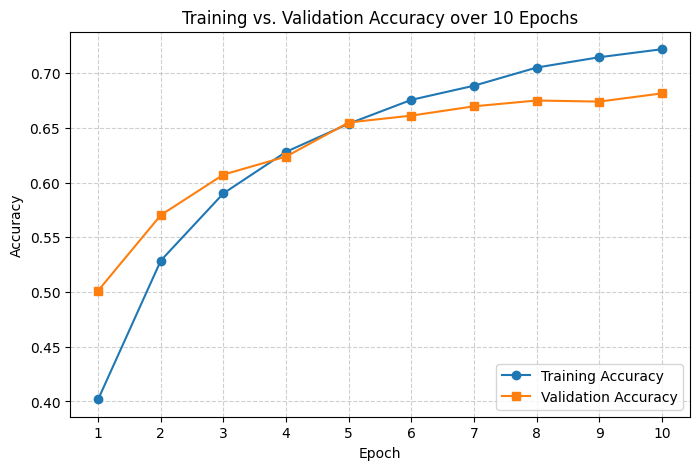

In [14]:
# Plot Training and Validation Accuracy
plt.figure(figsize=(8, 5))
plt.plot(range(1, 10 + 1), history.history['accuracy'], label='Training Accuracy', marker='o')
plt.plot(range(1, 10 + 1), history.history['val_accuracy'], label='Validation Accuracy', marker='s')

plt.title('Training vs. Validation Accuracy over 10 Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.xticks(range(1, 10 + 1))
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# **Question 2**

In [15]:
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

In [16]:
# Load Dataset & Select Specified Features
data = load_breast_cancer()
X_full = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

selected_features = ['worst compactness', 'worst concavity', 'worst area']
X = X_full[selected_features]

# Split Data (using standard random_state=42 and stratification for reproducibility)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Scale Features (Essential for SVM)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [17]:
# Part (i): Linear Kernel SVM
svm_linear = SVC(kernel='linear', random_state=42)
svm_linear.fit(X_train_scaled, y_train)
y_pred_linear = svm_linear.predict(X_test_scaled)
acc_linear = accuracy_score(y_test, y_pred_linear)

In [18]:
# Part (ii): RBF Kernel SVM with C = 2
svm_rbf = SVC(kernel='rbf', C=2.0, random_state=42)
svm_rbf.fit(X_train_scaled, y_train)
y_pred_rbf = svm_rbf.predict(X_test_scaled)
acc_rbf = accuracy_score(y_test, y_pred_rbf)

In [19]:
# Print Results
print(f"Accuracy with Linear Kernel:         {acc_linear * 100:.2f}% ({acc_linear:.4f})")
print(f"Accuracy with RBF Kernel (C=2.0):    {acc_rbf * 100:.2f}% ({acc_rbf:.4f})")

Accuracy with Linear Kernel:         93.86% (0.9386)
Accuracy with RBF Kernel (C=2.0):    94.74% (0.9474)
